# 6. Robustez y prioridades: ¿por dónde empezar?

Dos preguntas finales:

1. **¿Las conclusiones dependen de los pesos del IPM?** Los pesos oficiales son una decisión metodológica.
   Si con otros pesos razonables el orden de los municipios casi no cambia, las conclusiones son sólidas.
2. **¿Dónde rinde más una intervención?** Se combinan dos cosas: cuántas personas sufren cada privación y
   qué tan lejos está el Chocó del resto del país en esa privación.

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)
from scipy.stats import spearmanr

In [2]:
base = datos.base_municipal()
ind = ipm.indicadores_presentes(base)
choco = base[base.es_choco].copy()

## 6.1 Cuatro formas de pesar las privaciones

- **Oficiales DANE**: 0,2 por dimensión, repartido dentro de cada dimensión.
- **Iguales por indicador**: 1/15 cada uno.
- **Inverso de la dispersión**: menos peso a los indicadores que varían mucho entre municipios.
- **Componente principal**: pesos según cuánto aporta cada indicador a la variación común.

In [3]:
esquemas = ipm.pesos_alternativos(base)
tabla_pesos = pd.DataFrame(esquemas)
tabla_pesos.index = [ETIQUETAS[i] for i in tabla_pesos.index]
display((tabla_pesos * 100).round(1))

puntajes = pd.DataFrame({n: ipm.privacion_ponderada_agregado(base, w) for n, w in esquemas.items()})
puntajes["municipio"], puntajes["es_choco"] = base["municipio"], base["es_choco"]

rangos = puntajes.loc[puntajes.es_choco, list(esquemas)].rank(ascending=False)
rangos.index = puntajes.loc[puntajes.es_choco, "municipio"]
print("Correlación de Spearman del orden de los 30 municipios del Chocó frente a los pesos oficiales:")
for n in esquemas:
    if n != "Oficiales DANE":
        print(f"  {n:<26} {spearmanr(rangos['Oficiales DANE'], rangos[n]).statistic:.3f}")

,Oficiales DANE,Iguales por indicador,Inverso de la dispersión,Componente principal
Analfabetismo,10.0,6.7,4.7,7.8
Bajo logro educativo,10.0,6.7,3.0,5.5
Barreras primera infancia,5.0,6.7,11.5,7.9
Inasistencia escolar,5.0,6.7,10.3,8.4
Rezago escolar,5.0,6.7,4.9,8.8
Trabajo infantil,5.0,6.7,27.2,3.4
Dependencia económica,10.0,6.7,2.9,7.8
Empleo informal,10.0,6.7,5.5,6.9
Sin aseguramiento en salud,10.0,6.7,5.8,6.1
Barreras de acceso a salud,10.0,6.7,9.2,2.5


Correlación de Spearman del orden de los 30 municipios del Chocó frente a los pesos oficiales:
  Iguales por indicador      0.969
  Inverso de la dispersión   0.956
  Componente principal       0.970


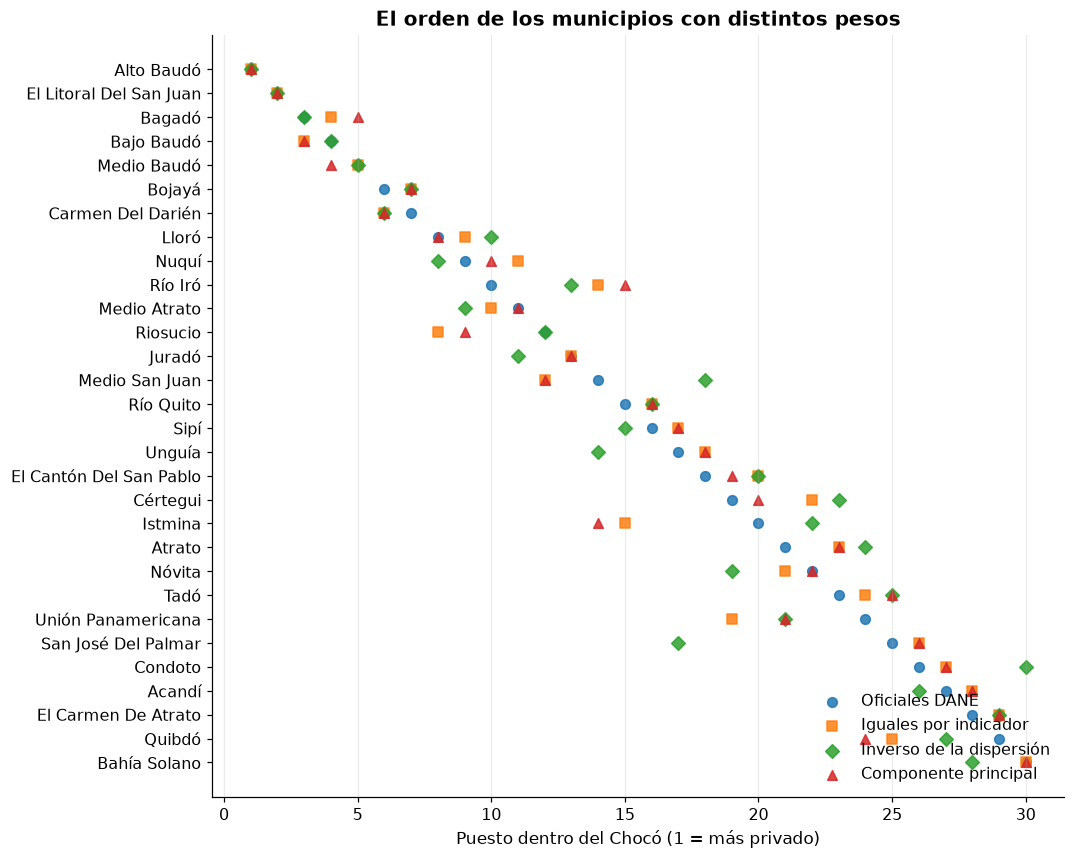

Proporción de municipios del Chocó en el 25 % más privado del país, según el esquema de pesos:
  Oficiales DANE             87 %
  Iguales por indicador      93 %
  Inverso de la dispersión   90 %
  Componente principal       97 %


In [4]:
orden = rangos.sort_values("Oficiales DANE")
fig, ax = plt.subplots(figsize=(10, 9))
for n, marcador in zip(esquemas, "osD^"):
    ax.scatter(orden[n], orden.index, marker=marcador, s=40, label=n, alpha=0.85)
ax.invert_yaxis()
ax.set(xlabel="Puesto dentro del Chocó (1 = más privado)", title="El orden de los municipios con distintos pesos")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
guardar(fig, "06_robustez_pesos")
plt.show()

print("Proporción de municipios del Chocó en el 25 % más privado del país, según el esquema de pesos:")
for n in esquemas:
    corte = puntajes[n].quantile(0.75)
    print(f"  {n:<26} {(puntajes.loc[puntajes.es_choco, n] >= corte).mean() * 100:.0f} %")

## 6.2 Personas privadas en cada indicador

Porcentaje de hogares privados × población del municipio. Es una aproximación (el porcentaje es de hogares y
la población es de personas), pero sirve para dimensionar.

In [5]:
if "poblacion_total" in base:
    personas = choco[ind].mul(choco["poblacion_total"], axis=0).div(100).sum()
    pct_choco = 100 * personas / choco["poblacion_total"].sum()
    resto = base[~base.es_choco]
    pct_resto = resto[ind].mul(resto["poblacion_total"], axis=0).sum() / resto["poblacion_total"].sum()
    prioridad = pd.DataFrame({
        "Personas en hogares privados (aprox.)": personas.round(-2),
        "% Chocó": pct_choco,
        "% resto del país": pct_resto,
    })
    prioridad["Brecha (pp)"] = prioridad["% Chocó"] - prioridad["% resto del país"]
    # Personas que saldrían de la privación si el Chocó llegara al nivel del resto del país
    prioridad["Personas para cerrar la brecha"] = (prioridad["Brecha (pp)"].clip(lower=0) / 100
                                                   * choco["poblacion_total"].sum()).round(-2)
    prioridad.index = [ETIQUETAS[i] for i in prioridad.index]
    prioridad = prioridad.sort_values("Personas para cerrar la brecha", ascending=False)
    display(prioridad.round(1))
    prioridad.round(1).to_csv(REPORTES / "prioridades_choco.csv")

,Personas en hogares privados (aprox.),% Chocó,% resto del país,Brecha (pp),Personas para cerrar la brecha
Eliminación inadecuada de excretas,"387,000.0",72.4,13.3,59.1,"316,100.0"
Sin fuente de agua mejorada,"366,600.0",68.5,11.9,56.7,"303,100.0"
Dependencia económica,"290,800.0",54.4,31.5,22.9,"122,400.0"
Bajo logro educativo,"344,900.0",64.5,45.9,18.6,"99,300.0"
Analfabetismo,"139,200.0",26.0,10.4,15.7,"83,900.0"
Paredes inadecuadas,"100,000.0",18.7,4.0,14.7,"78,900.0"
Rezago escolar,"153,200.0",28.6,15.8,12.8,"68,500.0"
Empleo informal,"496,100.0",92.8,80.7,12.1,"64,700.0"
Sin aseguramiento en salud,"125,100.0",23.4,17.0,6.4,"34,300.0"
Barreras primera infancia,"42,800.0",8.0,2.2,5.8,"31,000.0"


## 6.3 Matriz de prioridades

Eje horizontal: qué tan común es la privación en el Chocó. Eje vertical: qué tan lejos está del resto del país.
Arriba a la derecha quedan las privaciones **frecuentes y con brecha grande**: las que más pesan.

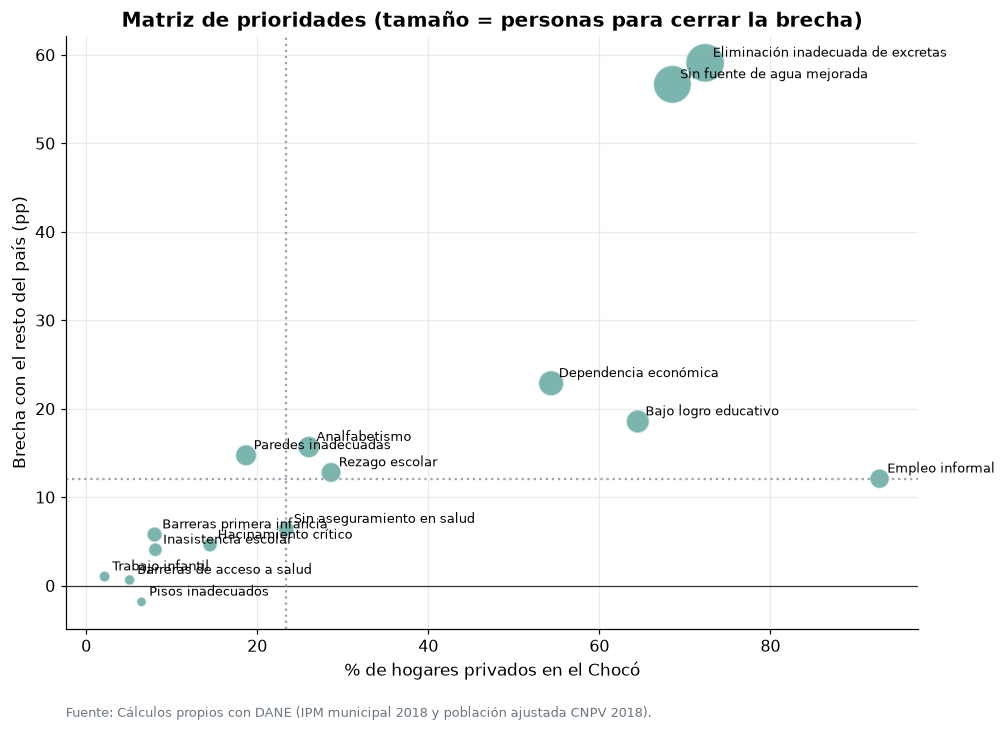

In [6]:
if "poblacion_total" in base:
    fig, ax = plt.subplots(figsize=(10, 7))
    tam = prioridad["Personas para cerrar la brecha"].clip(lower=1)
    ax.scatter(prioridad["% Chocó"], prioridad["Brecha (pp)"], s=40 + 600 * tam / tam.max(), color=CHOCO, alpha=0.55,
               edgecolor="white")
    for nombre, f in prioridad.iterrows():
        ax.annotate(nombre, (f["% Chocó"], f["Brecha (pp)"]), fontsize=8.5, xytext=(5, 4), textcoords="offset points")
    ax.axhline(0, color="#333", lw=0.8)
    ax.axvline(prioridad["% Chocó"].median(), color="#9aa5b1", ls=":")
    ax.axhline(prioridad["Brecha (pp)"].median(), color="#9aa5b1", ls=":")
    ax.set(xlabel="% de hogares privados en el Chocó", ylabel="Brecha con el resto del país (pp)",
           title="Matriz de prioridades (tamaño = personas para cerrar la brecha)")
    fuente(ax, "Cálculos propios con DANE (IPM municipal 2018 y población ajustada CNPV 2018).")
    guardar(fig, "06_matriz_prioridades")
    plt.show()

## 6.4 Simulación: ¿qué pasa si se cierra una brecha?

Para cada indicador, se lleva a cada municipio del Chocó al nivel **mediano del resto del país** (solo si
está peor) y se recalcula el puntaje promedio de privación. La caída muestra cuánto se movería la privación
total con esa sola mejora. Es un ejercicio mecánico: no dice cuánto cuesta ni qué tan fácil es lograrlo.

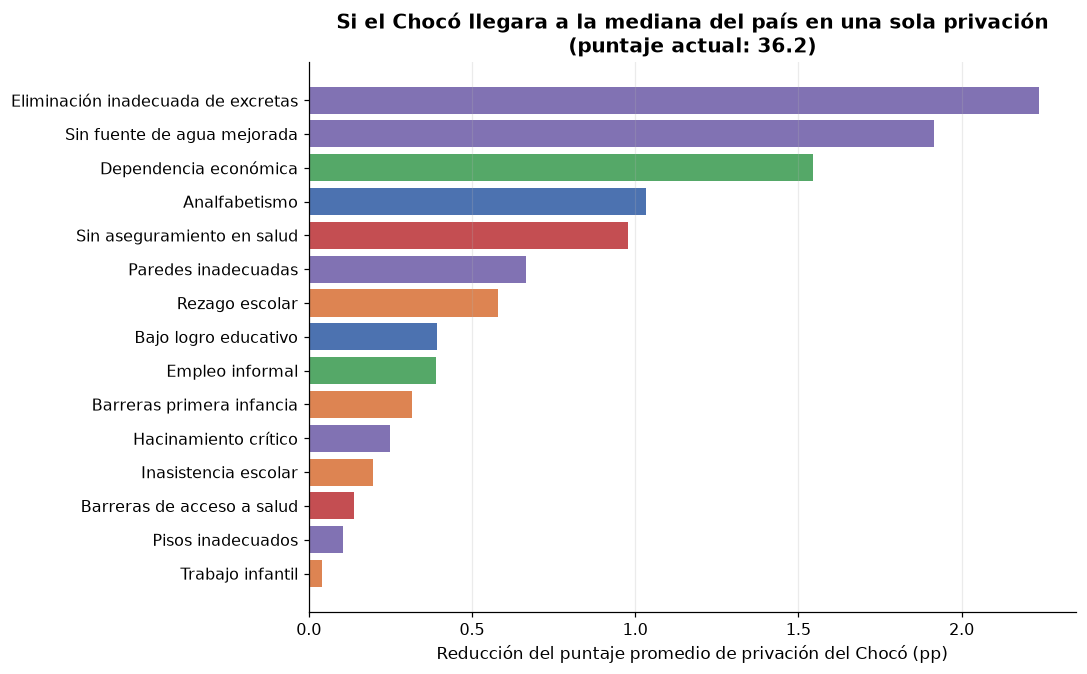

In [7]:
w = ipm.pesos(ind)
mediana_resto = base.loc[~base.es_choco, ind].median()
actual = ipm.privacion_ponderada_agregado(choco, w)
pob = choco["poblacion_total"] if "poblacion_total" in choco else pd.Series(1, index=choco.index)
actual_dep = (actual * pob).sum() / pob.sum()
sim = {}
for i in ind:
    c = choco.copy()
    c[i] = np.minimum(c[i], mediana_resto[i])
    nuevo = ipm.privacion_ponderada_agregado(c, w)
    sim[ETIQUETAS[i]] = actual_dep - (nuevo * pob).sum() / pob.sum()
sim = pd.Series(sim).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
clave_de = {ETIQUETAS[k]: k for k in ind}
ax.barh(sim.index, sim.values, color=[DIMENSION_COLORES[IPM_INDICADORES[clave_de[e]][0]] for e in sim.index])
ax.set(xlabel="Reducción del puntaje promedio de privación del Chocó (pp)",
       title=f"Si el Chocó llegara a la mediana del país en una sola privación\n(puntaje actual: {actual_dep:.1f})")
ax.grid(axis="y", visible=False)
guardar(fig, "06_simulacion")
plt.show()

## 6.5 Resumen por municipio

Una ficha corta por municipio: IPM total y rural, su peor privación frente al país y su tipología.

In [8]:
tipos = pd.read_csv(REPORTES / "tipologias_municipios.csv", dtype={"cod_mpio": str}) \
    if (REPORTES / "tipologias_municipios.csv").exists() else None
brecha_mpio = choco[ind] - mediana_resto
ficha = pd.DataFrame({
    "cod_mpio": choco["cod_mpio"],
    "municipio": choco["municipio"],
    "IPM": choco["ipm"],
    "IPM rural": choco.get("ipm_rural"),
    "IPM cabecera": choco.get("ipm_cabecera"),
    "Mayor brecha con el país": brecha_mpio.idxmax(axis=1).map(ETIQUETAS),
    "Brecha (pp)": brecha_mpio.max(axis=1),
})
if tipos is not None:
    ficha = ficha.merge(tipos, on="cod_mpio", how="left")
ficha = ficha.sort_values("IPM", ascending=False).reset_index(drop=True)
display(ficha.round(1))
ficha.round(1).to_csv(REPORTES / "ficha_municipios_choco.csv", index=False)

,cod_mpio,municipio,IPM,IPM rural,IPM cabecera,Mayor brecha con el país,Brecha (pp),tipo
0,27025,Alto Baudó,90.6,92.4,77.7,Eliminación inadecuada de excretas,66.9,Tipo 6
1,27250,El Litoral Del San Juan,83.1,85.6,65.1,Eliminación inadecuada de excretas,64.6,Tipo 6
2,27073,Bagadó,81.0,91.1,49.2,Eliminación inadecuada de excretas,58.4,Tipo 6
3,27077,Bajo Baudó,80.4,87.0,55.1,Eliminación inadecuada de excretas,65.3,Tipo 5
4,27430,Medio Baudó,80.2,79.9,82.1,Eliminación inadecuada de excretas,64.3,Tipo 5
5,27150,Carmen Del Darién,77.8,79.9,64.2,Eliminación inadecuada de excretas,65.5,Tipo 5
6,27099,Bojayá,77.1,79.9,48.7,Eliminación inadecuada de excretas,58.9,Tipo 5
7,27425,Medio Atrato,76.6,78.0,61.7,Sin fuente de agua mejorada,63.2,Tipo 5
8,27580,Río Iró,75.1,76.6,72.3,Eliminación inadecuada de excretas,56.6,Tipo 4
9,27413,Lloró,74.4,83.4,59.0,Sin fuente de agua mejorada,58.7,Tipo 5


## Conclusiones del estudio

1. **El orden no depende de los pesos.** Si las correlaciones de 6.1 son altas, los municipios más privados
   lo son con cualquier esquema razonable: la focalización es robusta.
2. **Las prioridades salen de cruzar frecuencia y brecha.** Las privaciones de la esquina superior derecha
   de la matriz son donde el Chocó está peor *y* donde más personas se benefician.
3. **Cada municipio necesita su propia receta.** La ficha 6.5 muestra que la privación con mayor brecha cambia
   de un municipio a otro.

**Límites.** Los datos municipales son de 2018 y se trabajó con porcentajes agregados, no con hogares.
El siguiente paso natural es calcular el IPM hogar por hogar con los microdatos del censo (función
`ipm.alkire_foster`, ya incluida y probada), para obtener la intensidad y las contribuciones exactas por
municipio y por grupo étnico.